# NN_L14_zeroshot_confusion

**Confusion matrix (row percentages) of the best zero-shot CLIP classifier on the EuroSAT test set; per-class accuracy.**

Neural Networks and Deep Learning (NN), Lecture 14 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L14/NN_L14_zeroshot_confusion/NN_L14_zeroshot_confusion.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

zero-shot accuracy, AnnualCrop (%) = 58.0   [zs_class.AnnualCrop]
zero-shot accuracy, Forest (%) = 36.8   [zs_class.Forest]
zero-shot accuracy, HerbaceousVegetation (%) = 73.0   [zs_class.HerbaceousVegetation]
zero-shot accuracy, Highway (%) = 74.4   [zs_class.Highway]
zero-shot accuracy, Industrial (%) = 93.6   [zs_class.Industrial]
zero-shot accuracy, Pasture (%) = 34.8   [zs_class.Pasture]
zero-shot accuracy, PermanentCrop (%) = 18.6   [zs_class.PermanentCrop]
zero-shot accuracy, Residential (%) = 92.3   [zs_class.Residential]
zero-shot accuracy, River (%) = 50.4   [zs_class.River]
zero-shot accuracy, SeaLake (%) = 26.5   [zs_class.SeaLake]


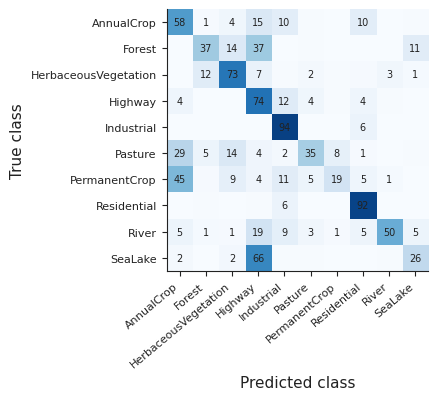

In [3]:
RES = REPO + 'lectures/L14/results/'
import json, urllib.request
Z = pd.read_csv(RES + 'eurosat_zeroshot.csv')
CLS = sorted(Z['true'].unique())
best = max([c for c in Z.columns if c[:3] in ('B32', 'B16')], key=lambda c: (Z[c] == Z['true']).mean())
CM = pd.crosstab(Z['true'], Z[best]).reindex(index=CLS, columns=CLS, fill_value=0).values
for i, c in enumerate(CLS):
    show(f'zs_class.{c}', f'zero-shot accuracy, {c} (%)', round(100 * float(CM[i, i] / CM[i].sum()), 1))
R = CM / CM.sum(1, keepdims=True) * 100
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.imshow(R, cmap='Blues', vmin=0, vmax=100)
ax.set_xticks(range(10))
ax.set_xticklabels(CLS, rotation=40, ha='right', fontsize=8)
ax.set_yticks(range(10))
ax.set_yticklabels(CLS, fontsize=8)
for a in range(10):
    for b in range(10):
        if R[a, b] >= 1:
            ax.text(b, a, f'{R[a, b]:.0f}', ha='center', va='center', fontsize=7)
ax.set_xlabel('Predicted class')
ax.set_ylabel('True class')
fig.savefig('zeroshot_confusion.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()